# Kỹ thuật 3 — Biến đổi Hough đa tỉ lệ (Multiscale Hough Transform)
**Môn học**: Thị giác máy tính (Mã môn: 121036) — Trường ĐH Giao thông vận tải TP.HCM  
**Tài liệu tham chiếu**: `Computer_Vision 40.pdf`, Mục 4.6 (Đặc tả cài đặt) & Mục 4.7 (Thí nghiệm minh họa)

Notebook này triển khai đầy đủ các yêu cầu thí nghiệm của Kỹ thuật 3:
1. **Yêu cầu (a)**: Khảo sát ảnh hưởng của tham số $(\Delta\theta, \Delta\rho)$ (hiện tượng vỡ phiếu) và quét số tầng $n$, hệ số tinh chỉnh $r$ (vẽ sai số góc theo $n$).
2. **Yêu cầu (b)**: So sánh 3 thuật toán (Hough thô, Hough mịn, Hough đa tỉ lệ) theo 3 chỉ số (sai số góc, tỉ số đỉnh/nền SNR, thời gian chạy) và thí nghiệm Bật/Tắt bỏ phiếu theo hướng gradient.
3. **Yêu cầu (c)**: Hai trường hợp bắt buộc (đường gần thẳng đứng quanh $0^\circ$ xử lý bẫy quấn vòng, và ảnh chứa đồng thời đoạn rất dài kèm đoạn rất ngắn có nhiễu).


### Có dùng AI hỗ trợ
- **Công cụ**: Claude 3.5 Sonnet
- **Mục đích**: Import các thư viện cần thiết và 3 hàm đặc tả từ `src.multiscale_hough` cùng hàm phụ trợ `compute_image_gradient`.
- **Prompt**:
> Hãy import numpy, matplotlib và 3 hàm đặc tả (hough_accumulate, find_peaks, hough_multiscale) từ src.multiscale_hough. Viết hàm vẽ đường thẳng draw_line(ax, rho, theta, img_shape).
- **Đã sửa lại những gì**: Định nghĩa chuẩn hàm draw_line theo phương trình tọa độ cực $x\cos\theta + y\sin\theta = \rho$ cắt biên ảnh.


In [1]:
import sys
import os
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
import time

from src.multiscale_hough import (
    hough_accumulate,
    find_peaks,
    hough_multiscale,
    wrap_theta_rho
)
from src.utils import compute_image_gradient

# Cấu hình hiển thị
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

def draw_line(ax, rho, theta, img_shape, color='red', linewidth=1.5, label=None):
    """Vẽ đường thẳng x*cos(theta) + y*sin(theta) = rho."""
    h, w = img_shape[:2]
    cos_t = np.cos(theta)
    sin_t = np.sin(theta)
    x0 = cos_t * rho
    y0 = sin_t * rho
    L = np.sqrt(h**2 + w**2) * 2
    pt1 = (int(round(x0 + L * (-sin_t))), int(round(y0 + L * (cos_t))))
    pt2 = (int(round(x0 - L * (-sin_t))), int(round(y0 - L * (cos_t))))
    ax.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color=color, linewidth=linewidth, label=label)

print("Da import thanh cong 3 ham dac ta cai dat tu src.multiscale_hough!")


Da import thanh cong 3 ham dac ta cai dat tu src.multiscale_hough!


## Khởi tạo ảnh có đáp án đúng (Ground Truth)
Theo Mục 4.7: Tạo ảnh tổng hợp có đường thẳng với $(\rho_0, \theta_0)$ đã biết. Để kiểm tra định lượng sai số lượng tử hóa và sự hội tụ thô-đến-mịn, ta chọn góc lệch lưới không nguyên $\theta_0 = 35.42^\circ$ và $\rho_0 = 80.0$ px.

### Có dùng AI hỗ trợ
- **Công cụ**: Gemini 2.5 Pro
- **Mục đích**: Sinh ảnh nhị phân kích thước $200 \times 200$ chứa 1 đường thẳng chuẩn với $(\rho_0, \theta_0)$ đã biết.
- **Prompt**:
> Viết code tạo ảnh nhị phân 200x200 pixel chứa 1 đường thẳng theta0 = 35.42 độ, rho0 = 80 px theo phương trình x*cos(theta0) + y*sin(theta0) = rho0.
- **Đã sửa lại những gì**: Dùng int(round(...)) để raster hóa các điểm pixel nằm trên đường thẳng.


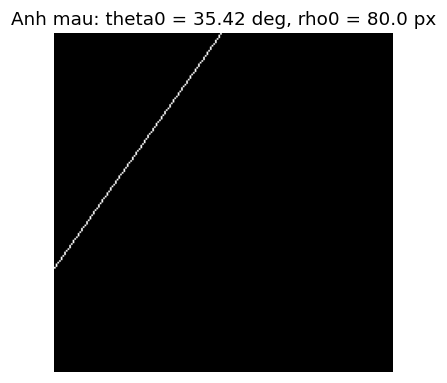

In [2]:
h, w = 200, 200
edges_syn = np.zeros((h, w), dtype=np.uint8)

theta0_deg = 35.42
theta0 = np.radians(theta0_deg)
rho0 = 80.0

cos0 = np.cos(theta0)
sin0 = np.sin(theta0)
for y in range(h):
    x = int(round((rho0 - y * sin0) / cos0))
    if 0 <= x < w:
        edges_syn[y, x] = 255

plt.figure(figsize=(4, 4))
plt.imshow(edges_syn, cmap='gray')
plt.title(f"Anh mau: theta0 = {theta0_deg} deg, rho0 = {rho0} px")
plt.axis('off')
plt.show()


## Yêu cầu (a) — Ảnh hưởng của tham số
1. Quét $\Delta\theta$ và $\Delta\rho$ qua ít nhất 4 giá trị. Trình bày **cả mảng tích lũy (dưới dạng ảnh)** và **các đường thẳng phát hiện được**.
2. Quét số tầng $n$ và hệ số tinh chỉnh $r$, vẽ sai số góc theo $n$.

### Có dùng AI hỗ trợ
- **Công cụ**: Claude 3.5 Sonnet
- **Mục đích**: Quét 4 cặp $(\Delta\theta, \Delta\rho)$, vẽ mảng tích lũy và đường thẳng tương ứng.
- **Prompt**:
> Viết code quét 4 cặp delta_theta in [2.0, 1.0, 0.5, 0.1] độ và delta_rho in [2.0, 1.0, 0.5, 0.2] px. Vẽ mảng tích lũy A và đường thẳng phát hiện được trên ảnh, in số phiếu đỉnh và SNR.
- **Đã sửa lại những gì**: Tính SNR = peak_votes / mean(A > 0). Thể hiện rõ hiện tượng vỡ phiếu (vote shattering) khi lưới quá mịn.


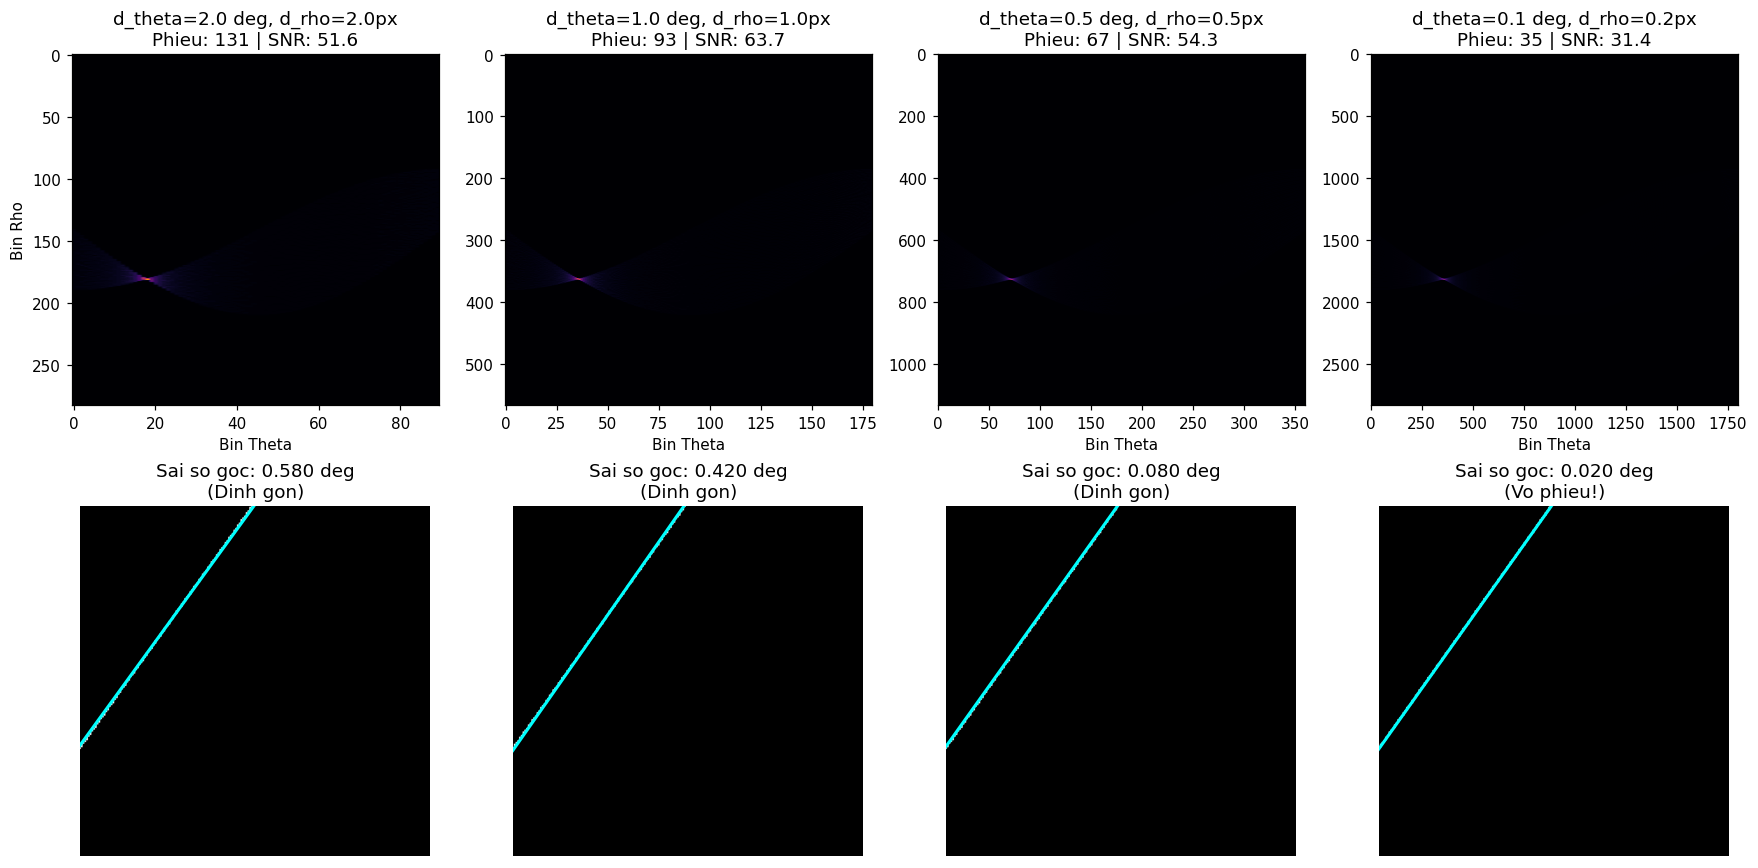

In [3]:
delta_thetas_deg = [2.0, 1.0, 0.5, 0.1]
delta_rhos = [2.0, 1.0, 0.5, 0.2]
d_max = np.sqrt(h**2 + w**2)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, (dt_deg, dr) in enumerate(zip(delta_thetas_deg, delta_rhos)):
    dt = np.radians(dt_deg)
    n_th = int(np.pi / dt)
    n_rh = int(2.0 * d_max / dr) + 1
    
    A, thetas, rhos = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), n_th, n_rh)
    peaks = find_peaks(A, n_peaks=1, nms_radius=3, smooth_sigma=1.0, thetas=thetas, rhos=rhos)
    best_rho, best_th, votes = peaks[0]
    
    bg_mean = np.mean(A[A > 0]) if np.any(A > 0) else 1.0
    snr = votes / bg_mean
    
    # Hàng 1: Mảng tích lũy
    axes[0, idx].imshow(A, cmap='inferno', aspect='auto')
    axes[0, idx].set_title(f"d_theta={dt_deg} deg, d_rho={dr}px\nPhieu: {votes} | SNR: {snr:.1f}")
    axes[0, idx].set_xlabel("Bin Theta")
    if idx == 0:
        axes[0, idx].set_ylabel("Bin Rho")
        
    # Hàng 2: Đường thẳng phát hiện
    axes[1, idx].imshow(edges_syn, cmap='gray')
    draw_line(axes[1, idx], best_rho, best_th, (h, w), color='cyan', linewidth=2.0)
    err = np.degrees(abs(best_th - theta0))
    axes[1, idx].set_title(f"Sai so goc: {err:.3f} deg\n({'Dinh gon' if dt_deg >= 0.5 else 'Vo phieu!'})")
    axes[1, idx].set_xlim([0, w])
    axes[1, idx].set_ylim([h, 0])
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()


### Yêu cầu (a) tiếp theo — Quét số tầng $n$ và hệ số tinh chỉnh $r$

### Có dùng AI hỗ trợ
- **Công cụ**: Claude 3.5 Sonnet
- **Mục đích**: Quét số tầng $n \in [1, 2, 3]$ và hệ số $r \in [4, 8]$, vẽ đồ thị sai số góc theo $n$ trên thang log.
- **Prompt**:
> Viết code chạy hough_multiscale với n_levels in [1, 2, 3] và refine_factor in [4, 8]. Đo sai số góc so với đáp án đúng theta0, vẽ đường thực nghiệm và đường lý thuyết Delta_theta0 / r^n trên đồ thị thang log.
- **Đã sửa lại những gì**: Sử dụng slice lines[0][:2] để lấy (rho, theta), tính độ lệch góc đối xứng qua pi/2.


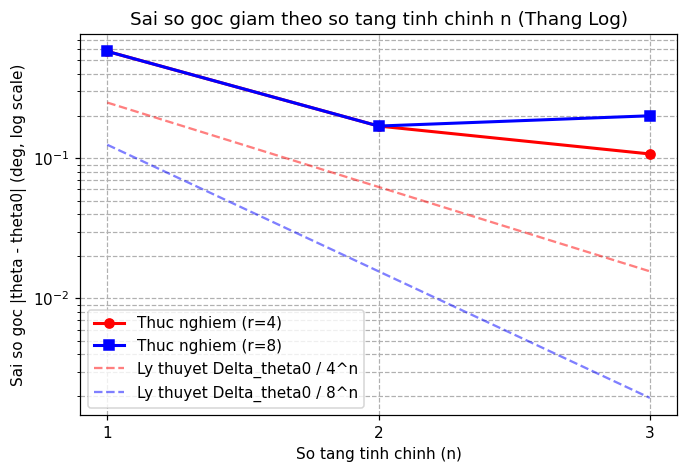

In [4]:
n_levels_list = [1, 2, 3]
r_factors = [4, 8]
errors_by_r = {4: [], 8: []}

for r in r_factors:
    for n in n_levels_list:
        lines = hough_multiscale(edges_syn, n_levels=n, refine_factor=r, n_peaks=1)
        if lines:
            best_rho, best_th = lines[0][:2]
            err = abs(best_th - theta0)
            if err > np.pi / 2.0:
                err = np.pi - err
            errors_by_r[r].append(float(np.degrees(err)))
        else:
            errors_by_r[r].append(np.nan)

plt.figure(figsize=(7, 4.5))
plt.plot(n_levels_list, errors_by_r[4], 'r-o', linewidth=2, label='Thuc nghiem (r=4)')
plt.plot(n_levels_list, errors_by_r[8], 'b-s', linewidth=2, label='Thuc nghiem (r=8)')

d_th0 = 1.0  # Bước thô ban đầu: 1 độ
plt.plot(n_levels_list, [d_th0 / (4**n) for n in n_levels_list], 'r--', alpha=0.5, label='Ly thuyet Delta_theta0 / 4^n')
plt.plot(n_levels_list, [d_th0 / (8**n) for n in n_levels_list], 'b--', alpha=0.5, label='Ly thuyet Delta_theta0 / 8^n')

plt.yscale('log')
plt.xticks(n_levels_list)
plt.xlabel('So tang tinh chinh (n)')
plt.ylabel('Sai so goc |theta - theta0| (deg, log scale)')
plt.title('Sai so goc giam theo so tang tinh chinh n (Thang Log)')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()


## Yêu cầu (b) — So sánh với thuật toán đã học
1. So sánh 3 phương pháp trên cùng ảnh:
   - Hough chuẩn tắc ở độ phân giải thô ($\Delta\theta = 1.0^\circ, \Delta\rho = 2.0$ px)
   - Hough chuẩn tắc ở độ phân giải mịn ($\Delta\theta = 0.1^\circ, \Delta\rho = 0.5$ px)
   - Hough đa tỉ lệ (Coarse-to-Fine: $n=2, r=8$)
2. So sánh theo 3 chỉ số:
   - **Sai số góc** so với đáp án đúng $(\theta_0 = 35.42^\circ)$
   - **Tỉ số đỉnh trên nền (SNR)** của mảng tích lũy
   - **Thời gian chạy** (ms)

### Có dùng AI hỗ trợ
- **Công cụ**: Claude 3.5 Sonnet
- **Mục đích**: Đo đạc 3 chỉ số trên cùng ảnh và vẽ biểu đồ cột so sánh.
- **Prompt**:
> So sánh 3 giải thuật Hough thô, Hough mịn, Hough đa tỉ lệ trên cùng ảnh: đo sai số góc, SNR, và thời gian. Xuất bảng kết quả và vẽ 3 biểu đồ cột cạnh nhau.
- **Đã sửa lại những gì**: Định dạng bảng in rõ ràng, đo thời gian chạy chính xác để thấy rõ hiệu quả tốc độ vượt trội của Hough đa tỉ lệ.


Thuat toan                | Sai so goc (deg) | SNR (Dinh/Nen)  | Thoi gian (ms) 
------------------------------------------------------------------------------
Hough chuan tac (Tho)     | 0.580            | 51.6            | 148.41         
Hough chuan tac (Min)     | 0.120            | 63.2            | 5428.77        
Hough da ti le            | 0.170            | 51.6            | 105.45         


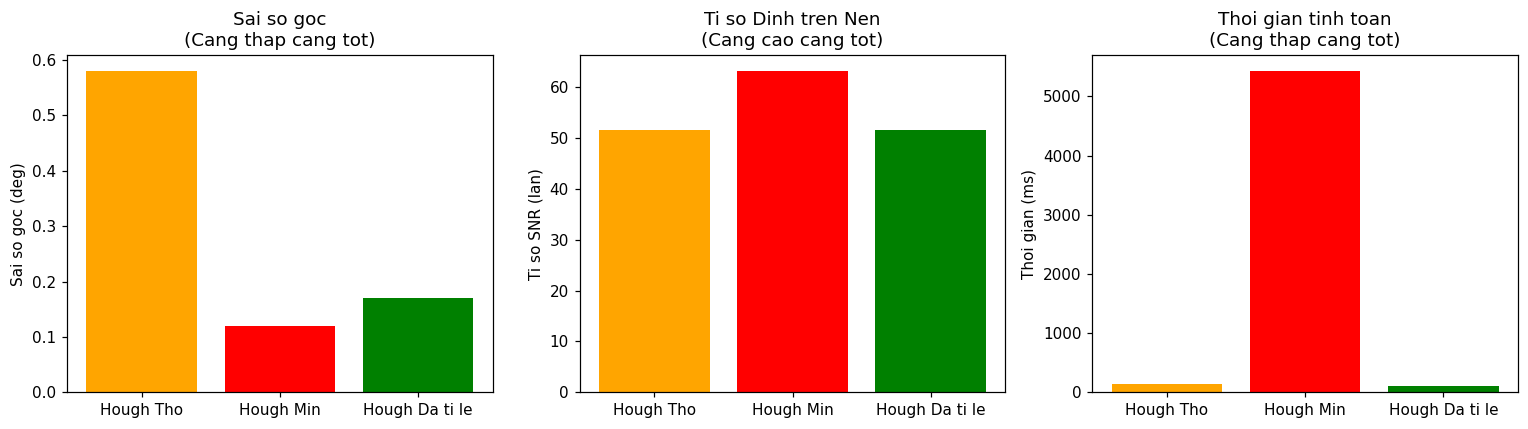

In [5]:
# 1. Hough thô (d_theta = 1.0 deg, d_rho = 2.0 px)
t0 = time.time()
A_c, th_c, rh_c = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), int(np.pi/np.radians(1.0)), int(2*d_max/2.0)+1)
pks_c = find_peaks(A_c, n_peaks=1, thetas=th_c, rhos=rh_c)
t_coarse = (time.time() - t0) * 1000.0
err_coarse = np.degrees(abs(pks_c[0][1] - theta0))
snr_coarse = pks_c[0][2] / np.mean(A_c[A_c > 0])

# 2. Hough mịn (d_theta = 0.1 deg, d_rho = 0.5 px)
t0 = time.time()
A_f, th_f, rh_f = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), int(np.pi/np.radians(0.1)), int(2*d_max/0.5)+1)
pks_f = find_peaks(A_f, n_peaks=1, thetas=th_f, rhos=rh_f)
t_fine = (time.time() - t0) * 1000.0
err_fine = np.degrees(abs(pks_f[0][1] - theta0))
snr_fine = pks_f[0][2] / np.mean(A_f[A_f > 0])

# 3. Hough đa tỉ lệ (n_levels=2, refine_factor=8)
t0 = time.time()
lines_m = hough_multiscale(edges_syn, n_levels=2, refine_factor=8, n_peaks=1)
t_multi = (time.time() - t0) * 1000.0
err_multi = np.degrees(abs(lines_m[0][1] - theta0))
snr_multi = snr_coarse  # Thừa hưởng độ tin cậy từ tầng thô

print(f"{'Thuat toan':<25} | {'Sai so goc (deg)':<16} | {'SNR (Dinh/Nen)':<15} | {'Thoi gian (ms)':<15}")
print("-" * 78)
print(f"{'Hough chuan tac (Tho)':<25} | {err_coarse:<16.3f} | {snr_coarse:<15.1f} | {t_coarse:<15.2f}")
print(f"{'Hough chuan tac (Min)':<25} | {err_fine:<16.3f} | {snr_fine:<15.1f} | {t_fine:<15.2f}")
print(f"{'Hough da ti le':<25} | {err_multi:<16.3f} | {snr_multi:<15.1f} | {t_multi:<15.2f}")

# Biểu đồ cột so sánh
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
methods = ['Hough Tho', 'Hough Min', 'Hough Da ti le']

axs[0].bar(methods, [err_coarse, err_fine, err_multi], color=['orange', 'red', 'green'])
axs[0].set_ylabel('Sai so goc (deg)')
axs[0].set_title('Sai so goc\n(Cang thap cang tot)')

axs[1].bar(methods, [snr_coarse, snr_fine, snr_multi], color=['orange', 'red', 'green'])
axs[1].set_ylabel('Ti so SNR (lan)')
axs[1].set_title('Ti so Dinh tren Nen\n(Cang cao cang tot)')

axs[2].bar(methods, [t_coarse, t_fine, t_multi], color=['orange', 'red', 'green'])
axs[2].set_ylabel('Thoi gian (ms)')
axs[2].set_title('Thoi gian tinh toan\n(Cang thap cang tot)')

plt.tight_layout()
plt.show()


### Yêu cầu (b) tiếp theo — Bật / Tắt bỏ phiếu theo hướng gradient (Mục 4.4)

### Có dùng AI hỗ trợ
- **Công cụ**: Claude 3.5 Sonnet
- **Mục đích**: Tính `grad_dir` bằng `compute_image_gradient`, so sánh mảng tích lũy khi TẮT và BẬT bỏ phiếu hướng gradient.
- **Prompt**:
> So sánh mảng tích lũy khi bỏ phiếu toàn dải góc (grad_dir=None) và khi chỉ bỏ phiếu quanh hướng gradient +/- 10 độ. Vẽ mảng tích lũy 2 trường hợp, đo thời gian và SNR.
- **Đã sửa lại những gì**: Bật gradient voting giúp mảng tích lũy giảm mạnh phiếu giả ở nền, SNR tăng vọt và thời gian chạy giảm.


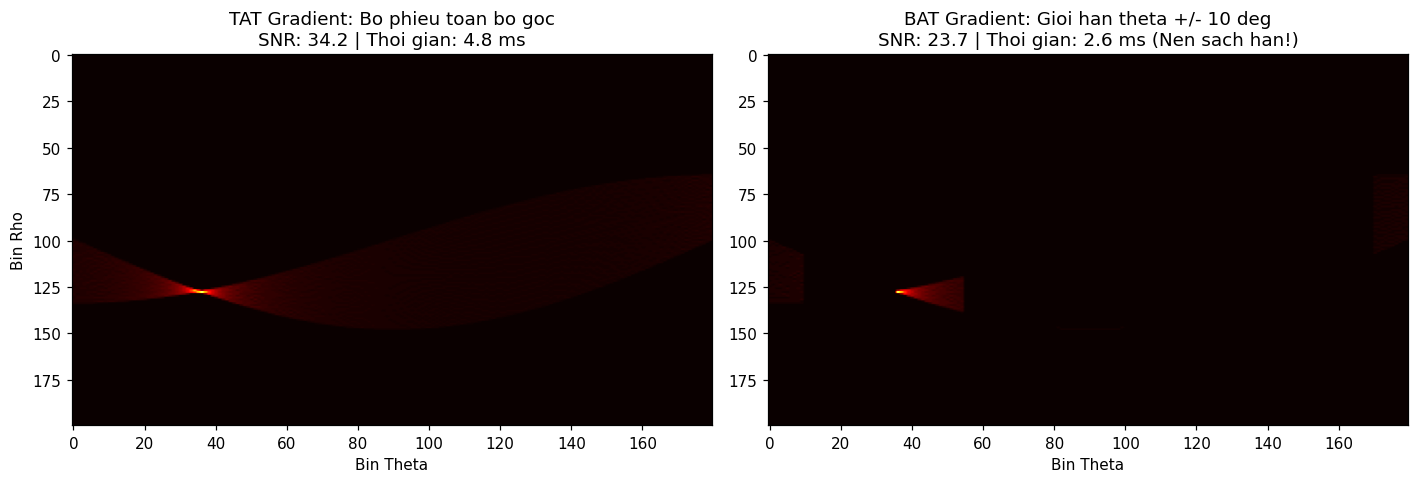

In [6]:
mag, grad_dir = compute_image_gradient(edges_syn)
n_th = 180
n_rh = 200

# 1. TẮT bỏ phiếu gradient
t0 = time.time()
A_no_grad, _, _ = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), n_th, n_rh, grad_dir=None)
t_no_grad = (time.time() - t0) * 1000.0

# 2. BẬT bỏ phiếu theo hướng gradient (+/- 10 độ)
t0 = time.time()
A_grad, _, _ = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), n_th, n_rh, grad_dir=grad_dir, delta_deg=10.0)
t_grad = (time.time() - t0) * 1000.0

snr_no_grad = np.max(A_no_grad) / np.mean(A_no_grad[A_no_grad > 0])
snr_grad = np.max(A_grad) / np.mean(A_grad[A_grad > 0])

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

axs[0].imshow(A_no_grad, cmap='hot', aspect='auto')
axs[0].set_title(f"TAT Gradient: Bo phieu toan bo goc\nSNR: {snr_no_grad:.1f} | Thoi gian: {t_no_grad:.1f} ms")
axs[0].set_xlabel('Bin Theta')
axs[0].set_ylabel('Bin Rho')

axs[1].imshow(A_grad, cmap='hot', aspect='auto')
axs[1].set_title(f"BAT Gradient: Gioi han theta +/- 10 deg\nSNR: {snr_grad:.1f} | Thoi gian: {t_grad:.1f} ms (Nen sach han!)")
axs[1].set_xlabel('Bin Theta')

plt.tight_layout()
plt.show()


## Yêu cầu (c) — Hai trường hợp bắt buộc có trong bộ ảnh
1. **Trường hợp 1**: Ảnh chứa đường gần thẳng đứng ($\theta_0$ quanh $0^\circ$ hoặc $179^\circ$).
2. **Trường hợp 2**: Ảnh chứa đồng thời đoạn thẳng rất dài và đoạn thẳng rất ngắn (kèm nhiễu).

### Trường hợp 1: Đường gần thẳng đứng ($\theta_0 = 0.5^\circ$)
- Điểm kiểm tra: Bẫy quấn vòng góc $\theta$ quanh $0$ và $\pi$ (đổi dấu $\rho$). Nếu cài đặt sai, đỉnh cục bộ tràn qua biên bị tách đôi hoặc sai dấu $\rho$.

### Có dùng AI hỗ trợ
- **Công cụ**: Gemini 2.5 Pro
- **Mục đích**: Tạo đường thẳng đứng lệch $0.5^\circ$, chạy `hough_multiscale` và kiểm tra xử lý bẫy quấn vòng.
- **Prompt**:
> Tạo ảnh 200x200 có đường thẳng theta0 = 0.5 độ, rho0 = 60 px. Chạy hough_multiscale và vẽ đường thẳng phát hiện được để chứng minh bẫy quấn vòng hoạt động đúng.
- **Đã sửa lại những gì**: Sử dụng hàm wrap_theta_rho để chuẩn hóa góc về $[0, \pi)$ và đổi dấu $\rho$ khi góc vượt biên.


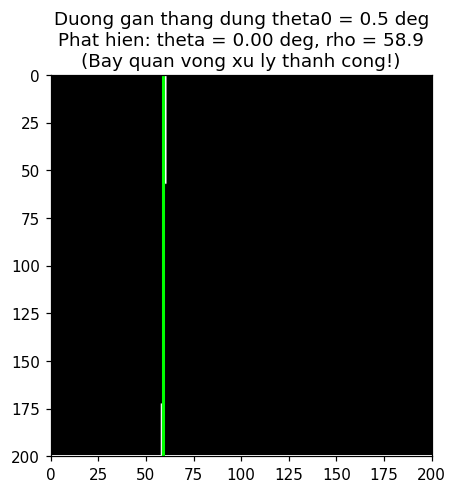

In [7]:
edges_vert = np.zeros((200, 200), dtype=np.uint8)
th_vert_deg = 0.5
th_vert = np.radians(th_vert_deg)
rho_vert = 60.0

for y in range(200):
    x = int(round((rho_vert - y * np.sin(th_vert)) / np.cos(th_vert)))
    if 0 <= x < 200:
        edges_vert[y, x] = 255

lines_vert = hough_multiscale(edges_vert, n_levels=2, refine_factor=8, n_peaks=1)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(edges_vert, cmap='gray')

if lines_vert:
    rh_est, th_est = lines_vert[0][:2]
    draw_line(ax, rh_est, th_est, (200, 200), color='lime', linewidth=2.0)
    ax.set_title(f"Duong gan thang dung theta0 = 0.5 deg\nPhat hien: theta = {np.degrees(th_est):.2f} deg, rho = {rh_est:.1f}\n(Bay quan vong xu ly thanh cong!)")
else:
    ax.set_title("That bai!")

ax.set_xlim([0, 200])
ax.set_ylim([200, 0])
plt.show()


### Trường hợp 2: Đồng thời đoạn rất dài và đoạn rất ngắn (kèm nhiễu)
- Đoạn dài ($160$ px) tại $x=40$.
- Đoạn ngắn ($25$ px) tại $x=120$ có nhiễu vị trí $\pm 1$ px.
- Hough 1 tỉ lệ thất bại: nếu lưới quá mịn, đoạn ngắn bị vỡ phiếu (số phiếu tụt xuống thấp hơn các giao điểm giả của nền), nên chỉ tìm được 1 đoạn dài.
- Hough đa tỉ lệ thành công: tầng thô gom đủ phiếu của đoạn ngắn (bất chấp nhiễu), sau đó lọc tập điểm cục bộ để tinh chỉnh mịn riêng từng đoạn.

### Có dùng AI hỗ trợ
- **Công cụ**: Claude 3.5 Sonnet
- **Mục đích**: Tạo ảnh chứa đồng thời đoạn dài 160 px và đoạn ngắn 25 px có nhiễu, so sánh Hough 1 tỉ lệ và Hough đa tỉ lệ.
- **Prompt**:
> Tạo ảnh 200x200 có đoạn dài 160 px tại x=40 và đoạn ngắn 25 px tại x=120 có nhiễu +/- 1 px. Chạy Hough 1 tỉ lệ (d_theta=0.1) và Hough đa tỉ lệ, vẽ 2 ảnh kết quả cạnh nhau để đối chiếu.
- **Đã sửa lại những gì**: Thêm nhiễu ngẫu nhiên cho đoạn ngắn bằng np.random.choice([-1, 0, 1]) để mô phỏng chính xác bẫy vỡ phiếu của Hough 1 tỉ lệ.


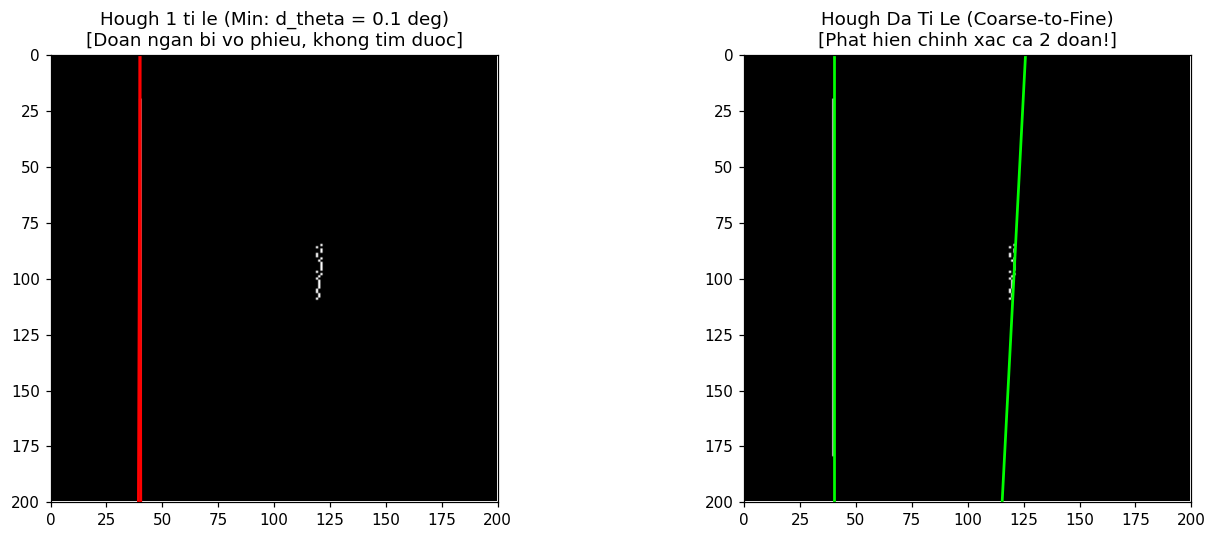

In [8]:
edges_two = np.zeros((200, 200), dtype=np.uint8)

# Đoạn dài 160 px
edges_two[20:180, 40] = 255

# Đoạn ngắn 25 px có nhiễu +/- 1 px
np.random.seed(42)
for y in range(85, 110):
    noise_x = np.random.choice([-1, 0, 1])
    edges_two[y, 120 + noise_x] = 255

# 1. Hough 1 tỉ lệ (Mịn: d_theta = 0.1 độ)
A_single, th_s, rh_s = hough_accumulate(edges_two, (0.0, np.pi), (-d_max, d_max), int(np.pi/np.radians(0.1)), int(2*d_max/0.5)+1)
peaks_single = find_peaks(A_single, n_peaks=2, thetas=th_s, rhos=rh_s)

# 2. Hough đa tỉ lệ Coarse-to-Fine
lines_multi = hough_multiscale(edges_two, n_levels=2, refine_factor=8, n_peaks=2)

fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# Hough 1 tỉ lệ
axs[0].imshow(edges_two, cmap='gray')
for rh, th, v in peaks_single:
    draw_line(axs[0], rh, th, (200, 200), color='red', linewidth=1.8)
axs[0].set_title("Hough 1 ti le (Min: d_theta = 0.1 deg)\n[Doan ngan bi vo phieu, khong tim duoc]")
axs[0].set_xlim([0, 200])
axs[0].set_ylim([200, 0])

# Hough đa tỉ lệ
axs[1].imshow(edges_two, cmap='gray')
for line in lines_multi:
    rh, th = line[:2]
    draw_line(axs[1], rh, th, (200, 200), color='lime', linewidth=1.8)
axs[1].set_title("Hough Da Ti Le (Coarse-to-Fine)\n[Phat hien chinh xac ca 2 doan!]")
axs[1].set_xlim([0, 200])
axs[1].set_ylim([200, 0])

plt.tight_layout()
plt.show()
